# XGBoost Baseline – Uttarakhand Forest Fire Prediction (static susceptibility)

Static spatial XGBoost baseline, built to mirror the Random Forest notebook (`02_RF_Baseline_Forest_Fire.ipynb`)
so the two tables can be compared one-to-one: same CSV, same 16 features, same 0.25° spatial blocks, same splits.

Workflow:

EDA → Feature Engineering → Random Split → Spatial Split (early stopping) → (optional tuning)
→ Spatial 5-fold CV → Evaluation → Feature Importance → Model Saving

Note: this CSV has no date/time dimension, so this model learns **where** fires happen (susceptibility),
not **when**. It is NOT the temporal baseline for the CNN-LSTM table.

## 1. Setup

In [2]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# !pip install xgboost      # uncomment on a fresh environment
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report)

In [6]:
SEED = 42
TARGET = "fire_occurred"
CSV_PATH = r"C:\Users\dell\OneDrive\Desktop\disaster detection\uttarakhand_grid_features(for_baseline_model).csv"   # change to your path
TUNE = False        # True = small hyper-parameter search (spatial CV on the TRAIN blocks only)
USE_GPU = False     # True on Colab GPU (device="cuda")
OUT_DIR = "."       # where figures / csv are saved

## 2. Load and inspect the data

In [7]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(60434, 16)


,longitude,latitude,NDVI,NDMI,temperature_2m,temperature_2m_max,dewpoint_temperature_2m,total_precipitation_sum,u_component_of_wind_10m,v_component_of_wind_10m,surface_pressure,volumetric_soil_water_layer_1,elevation,slope,aspect,fire_occurred
0,79.056237,31.454510,0.034391,0.188550,266.61887,272.42578,259.66250,0.001255,1.068875,0.566842,57139.035,0.111080,5012.1400,14.844332,199.069610,0
1,79.047253,31.445527,0.016374,0.381851,264.61670,270.03296,259.06317,0.001604,0.879129,0.616004,55585.973,0.186933,5200.7480,18.319778,190.935290,0
2,79.056237,31.445527,0.011619,0.468679,264.82630,270.37836,258.34160,0.001414,0.959130,0.724336,55237.586,0.155784,5150.1350,17.898663,154.888230,0
3,79.065220,31.445527,0.023675,0.383258,264.82630,270.37836,258.34160,0.001414,0.959130,0.724336,55237.586,0.155784,5194.6226,17.689997,198.592040,0
4,79.074203,31.445527,0.024967,0.321524,264.82630,270.37836,258.34160,0.001414,0.959130,0.724336,55237.586,0.155784,5139.0874,19.879358,125.371086,0


In [8]:
print(df.isnull().sum().sum(), "missing |", df.duplicated().sum(), "duplicate rows")
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True) * 100)

0 missing | 0 duplicate rows
fire_occurred
1    30789
0    29645
Name: count, dtype: int64
fire_occurred
1    50.946487
0    49.053513
Name: proportion, dtype: float64


**Observation:** `fire_occurred` = at least one MODIS/VIIRS detection in that 1 km cell during the study period, so ~51% of cells are positive.
The classes are nearly balanced, so no strong imbalance correction is needed. This is specific to the static dataset and is
not the prevalence of the temporal dataset (~0.9%), so PR-AUC here is **not** comparable with the CNN-LSTM table.

## 3. Feature engineering (identical to the RF notebook)

In [9]:
df = df.dropna().reset_index(drop=True)
df["wind_speed"] = np.sqrt(df["u_component_of_wind_10m"]**2 + df["v_component_of_wind_10m"]**2)
df["dewpoint_depression"] = df["temperature_2m"] - df["dewpoint_temperature_2m"]
df["aspect_sin"] = np.sin(np.deg2rad(df["aspect"]))
df["aspect_cos"] = np.cos(np.deg2rad(df["aspect"]))

FEATURES = ["NDVI", "NDMI", "temperature_2m", "temperature_2m_max", "dewpoint_temperature_2m",
            "total_precipitation_sum", "u_component_of_wind_10m", "v_component_of_wind_10m",
            "surface_pressure", "volumetric_soil_water_layer_1", "elevation", "slope",
            "wind_speed", "dewpoint_depression", "aspect_sin", "aspect_cos"]
X = df[FEATURES]
y = df[TARGET]
print(X.shape, y.shape)

(60434, 16) (60434,)


Longitude/latitude are **not** used as features, otherwise the model can memorise locations.

## 4. Spatial blocks (0.25°)

In [10]:
df["block"] = (df["longitude"] // 0.25).astype(int).astype(str) + "_" + (df["latitude"] // 0.25).astype(int).astype(str)
groups = df["block"]
print("blocks:", groups.nunique())

blocks: 104


## 5. Model and metric helpers

In [11]:
def make_xgb(**over):
    params = dict(
        n_estimators=600, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, tree_method="hist", eval_metric="aucpr",
        early_stopping_rounds=30, n_jobs=-1, random_state=SEED,
    )
    if USE_GPU:
        params["device"] = "cuda"
    params.update(over)
    return XGBClassifier(**params)

def metrics(yt, yp, pr):
    return dict(accuracy=accuracy_score(yt, yp), precision=precision_score(yt, yp),
                recall=recall_score(yt, yp), f1=f1_score(yt, yp),
                roc_auc=roc_auc_score(yt, pr), pr_auc=average_precision_score(yt, pr))

def spw(yy):
    # neg/pos on the TRAIN part; ~1 here because the static data is balanced
    return float((yy == 0).sum() / (yy == 1).sum())

def fit_with_es(Xa, ya, ga, **over):
    # carve an inner validation set out of the training blocks (whole blocks, so no spatial leakage)
    inner = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    i_tr, i_va = next(inner.split(Xa, ya, ga))
    m = make_xgb(scale_pos_weight=spw(ya.iloc[i_tr]), **over)
    m.fit(Xa.iloc[i_tr], ya.iloc[i_tr], eval_set=[(Xa.iloc[i_va], ya.iloc[i_va])], verbose=False)
    return m

results = {}

## 6. Random split (optimistic, for comparison only)

In [12]:
Xtr, Xte, ytr, yte, gtr, gte = train_test_split(X, y, groups, test_size=0.2, stratify=y, random_state=SEED)
# early stopping needs a validation set; a plain random 15% of train is fine for this "optimistic" run
Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=0.15, stratify=ytr, random_state=SEED)
m_rand = make_xgb(scale_pos_weight=spw(ya))
m_rand.fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False)
rand_proba = m_rand.predict_proba(Xte)[:, 1]
results["random_split"] = metrics(yte, (rand_proba >= 0.5).astype(int), rand_proba)
print("best iteration:", m_rand.best_iteration)
results["random_split"]

best iteration: 555


{'accuracy': 0.8490940680069496,
 'precision': 0.8269462884731442,
 'recall': 0.8900617083468658,
 'f1': 0.8573439699671516,
 'roc_auc': 0.9293086628492374,
 'pr_auc': 0.9242041922582893}

## 7. Spatial-block split (main result)

In [13]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(splitter.split(X, y, groups))
Xtr_s, ytr_s, gtr_s = X.iloc[tr], y.iloc[tr], groups.iloc[tr]
Xte_s, yte_s = X.iloc[te], y.iloc[te]
print("Train:", len(tr), "Test:", len(te))

Train: 50509 Test: 9925


### 7a. Optional hyper-parameter search
Runs only if `TUNE = True`. It uses spatial 3-fold CV **inside the training blocks**; the test blocks are never touched.

In [14]:
BEST = {}
if TUNE:
    space = {
        "max_depth": [3, 4, 5, 6, 8],
        "learning_rate": [0.03, 0.05, 0.1],
        "min_child_weight": [1, 5, 10, 20],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [1, 5, 10],
        "n_estimators": [200, 400, 600],
    }
    base = XGBClassifier(tree_method="hist", eval_metric="aucpr", n_jobs=1, random_state=SEED,
                         scale_pos_weight=spw(ytr_s), **({"device": "cuda"} if USE_GPU else {}))
    search = RandomizedSearchCV(base, space, n_iter=15, scoring="average_precision",
                                cv=GroupKFold(n_splits=3), n_jobs=1, random_state=SEED, verbose=1)
    search.fit(Xtr_s, ytr_s, groups=gtr_s)
    BEST = {k: v for k, v in search.best_params_.items()}
    print("Best params:", BEST, "| CV PR-AUC:", round(search.best_score_, 4))

In [15]:
xgb_s = fit_with_es(Xtr_s, ytr_s, gtr_s, **BEST)
print("best iteration:", xgb_s.best_iteration)

proba = xgb_s.predict_proba(Xte_s)[:, 1]
pred = (proba >= 0.5).astype(int)
results["spatial_split"] = metrics(yte_s, pred, proba)
results["spatial_split"]

best iteration: 299


{'accuracy': 0.7987909319899245,
 'precision': 0.767962308598351,
 'recall': 0.8807410266306446,
 'f1': 0.8204943820224719,
 'roc_auc': 0.8835940600432268,
 'pr_auc': 0.8790725736428859}

In [16]:
print(classification_report(yte_s, pred, target_names=["No fire", "Fire"]))

              precision    recall  f1-score   support

     No fire       0.84      0.71      0.77      4743
        Fire       0.77      0.88      0.82      5182

    accuracy                           0.80      9925
   macro avg       0.81      0.79      0.80      9925
weighted avg       0.80      0.80      0.80      9925



### 7b. Overfitting check (train vs spatial-test ROC-AUC)

In [17]:
train_auc = roc_auc_score(ytr_s, xgb_s.predict_proba(Xtr_s)[:, 1])
test_auc = results["spatial_split"]["roc_auc"]
print(f"Train ROC-AUC: {train_auc:.4f} | Spatial-test ROC-AUC: {test_auc:.4f} | Gap: {train_auc - test_auc:.4f}")

Train ROC-AUC: 0.9464 | Spatial-test ROC-AUC: 0.8836 | Gap: 0.0628


## 8. 5-fold spatial cross-validation

In [18]:
cv = []
for a_, b_ in GroupKFold(n_splits=5).split(X, y, groups):
    m = fit_with_es(X.iloc[a_], y.iloc[a_], groups.iloc[a_], **BEST)
    pr = m.predict_proba(X.iloc[b_])[:, 1]
    cv.append(metrics(y.iloc[b_], (pr >= 0.5).astype(int), pr))
cv = pd.DataFrame(cv)
cv.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
0,0.8580,0.8321,0.9299,0.8783,0.9176,0.9143
1,0.8049,0.7732,0.8576,0.8132,0.8910,0.8743
2,0.8540,0.8387,0.9060,0.8710,0.9216,0.9169
3,0.8143,0.7367,0.8908,0.8064,0.9012,0.8537
4,0.7924,0.7659,0.8678,0.8137,0.8786,0.8752


In [19]:
results["spatial_5fold_cv_mean"] = cv.mean().to_dict()
results["spatial_5fold_cv_std"] = cv.std().to_dict()

## 9. Results comparison

In [20]:
res = pd.DataFrame(results).T.round(4)
res.to_csv(f"{OUT_DIR}/static_xgb_results.csv")
res

,accuracy,precision,recall,f1,roc_auc,pr_auc
random_split,0.8491,0.8269,0.8901,0.8573,0.9293,0.9242
spatial_split,0.7988,0.7680,0.8807,0.8205,0.8836,0.8791
spatial_5fold_cv_mean,0.8247,0.7893,0.8904,0.8365,0.9020,0.8869
spatial_5fold_cv_std,0.0296,0.0443,0.0291,0.0350,0.0180,0.0276


#### Observation
(Fill in after the run.) Compare `random_split` with `spatial_split`: the drop shows how much a random split
overstates performance when neighbouring cells share ERA5 weather. The spatial 5-fold mean ± std is the main baseline number.

## 10. Confusion matrix

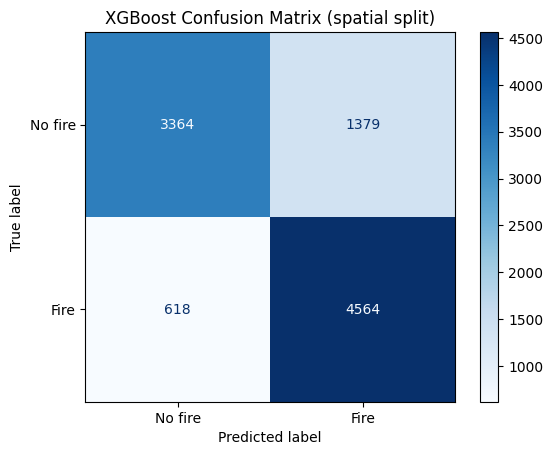

In [21]:
cm = confusion_matrix(yte_s, pred)
ConfusionMatrixDisplay(cm, display_labels=["No fire", "Fire"]).plot(cmap="Blues")
plt.title("XGBoost Confusion Matrix (spatial split)")
plt.savefig(f"{OUT_DIR}/static_xgb_confusion_matrix.png", dpi=150)
plt.show()

False negatives (actual fire, predicted no fire) matter most for an early-warning system.

## 11. ROC and Precision-Recall curves

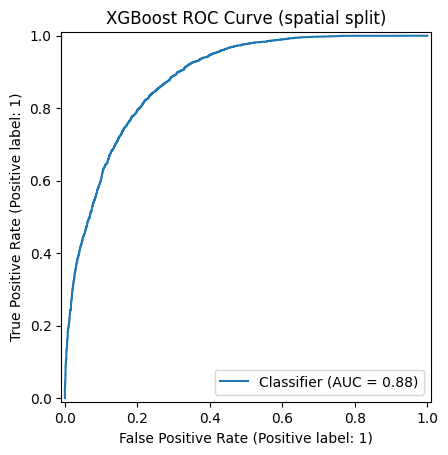

In [22]:
RocCurveDisplay.from_predictions(yte_s, proba)
plt.title("XGBoost ROC Curve (spatial split)")
plt.savefig(f"{OUT_DIR}/static_xgb_roc_curve.png", dpi=150)
plt.show()

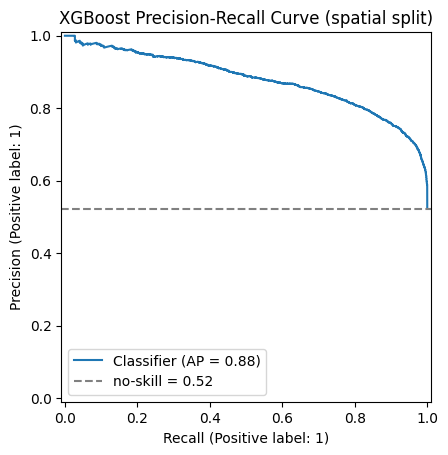

In [23]:
PrecisionRecallDisplay.from_predictions(yte_s, proba)
plt.axhline(yte_s.mean(), ls="--", c="gray", label=f"no-skill = {yte_s.mean():.2f}")
plt.legend()
plt.title("XGBoost Precision-Recall Curve (spatial split)")
plt.savefig(f"{OUT_DIR}/static_xgb_precision_recall_curve.png", dpi=150)
plt.show()

## 12. Threshold table (recall vs precision)
The threshold is picked from this table using the **training blocks' inner validation**, not the test blocks.
Here it is only printed on the spatial test blocks to show the trade-off; do not tune on it.

In [24]:
rows = []
for t in np.arange(0.2, 0.85, 0.05):
    p_ = (proba >= t).astype(int)
    rows.append((round(t, 2), recall_score(yte_s, p_), precision_score(yte_s, p_)))
pd.DataFrame(rows, columns=["threshold", "recall", "precision"]).round(3)

,threshold,recall,precision
0,0.20,0.973,0.687
1,0.25,0.964,0.702
2,0.30,0.951,0.717
3,0.35,0.939,0.729
4,0.40,0.925,0.743
5,0.45,0.906,0.752
6,0.50,0.881,0.768
7,0.55,0.854,0.784
8,0.60,0.822,0.802
9,0.65,0.783,0.816


## 13. Feature importance

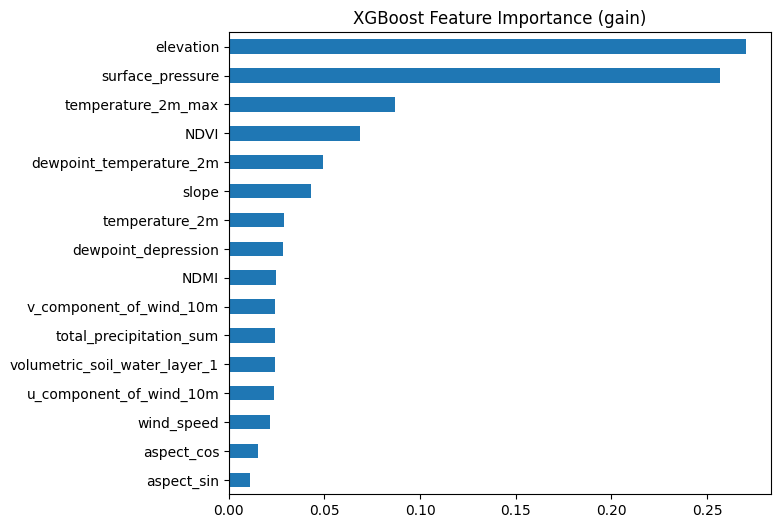

In [25]:
imp = pd.Series(xgb_s.feature_importances_, index=FEATURES).sort_values()   # gain-based
imp.plot.barh(figsize=(7, 6), color="#1f77b4")
plt.title("XGBoost Feature Importance (gain)")
plt.savefig(f"{OUT_DIR}/static_xgb_feature_importance.png", dpi=150)
plt.show()

In [26]:
fi = imp.sort_values(ascending=False).reset_index()
fi.columns = ["feature", "importance"]
fi.to_csv(f"{OUT_DIR}/static_xgb_feature_importance.csv", index=False)
fi

,feature,importance
0,elevation,0.270091
1,surface_pressure,0.256952
2,temperature_2m_max,0.087075
3,NDVI,0.068632
4,dewpoint_temperature_2m,0.049178
5,slope,0.042710
6,temperature_2m,0.028977
7,dewpoint_depression,0.028224
8,NDMI,0.024623
9,v_component_of_wind_10m,0.024238


Permutation importance on the held-out spatial blocks is a more reliable check than gain
(gain is biased towards high-cardinality / correlated features such as `surface_pressure` vs `temperature_2m`, r = 0.99).

In [27]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(xgb_s, Xte_s, yte_s, scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=1)
pi_df = (pd.DataFrame({"feature": FEATURES, "perm_importance": pi.importances_mean})
         .sort_values("perm_importance", ascending=False))
pi_df.to_csv(f"{OUT_DIR}/static_xgb_permutation_importance.csv", index=False)
pi_df

,feature,perm_importance
10,elevation,0.157286
11,slope,0.073895
0,NDVI,0.039227
1,NDMI,0.028278
5,total_precipitation_sum,0.013932
13,dewpoint_depression,0.013725
4,dewpoint_temperature_2m,0.011261
3,temperature_2m_max,0.009511
2,temperature_2m,0.007374
6,u_component_of_wind_10m,0.004805


## 14. Save model

In [28]:
os.makedirs("../models", exist_ok=True)
xgb_s.save_model("../models/xgboost_baseline.json")
json.dump({"features": FEATURES, "params": {k: str(v) for k, v in xgb_s.get_params().items()}},
          open("../models/xgboost_baseline_meta.json", "w"), indent=2)

## 15. Limitations
- Static features (not aligned to a fire date): the model learns *where* fires happen, not *when*.
- Classes are ~51/49 here vs ~0.9% positives in the time-series data, so PR-AUC is not directly comparable with the CNN-LSTM.
- ERA5-Land is ~9 km, so neighbouring 1 km cells share identical weather values; this is why spatial-block validation is used.
- The label is "any MODIS/VIIRS detection" (includes cropland / grass fires), not strictly forest fire.
- Aspect was bilinearly resampled before sin/cos, so the circular averaging issue is not fully removed.
- Gain-based importance can be distorted by correlated features; use permutation importance for interpretation.